# BT4012 Kaggle 2026: detecting illicit Bitcoin transactions
**Student:** e1122390 · **Public leaderboard ROC-AUC:** 0.96974

This notebook goes from the raw competition files in `data/` to `Submission/e1122390.csv`. It ranks the test
transactions (time steps 36–49) by how likely they are to be illicit, using the labelled transactions from steps
1–35 and the links between transactions.

**Steps**
1. Load and check the data.
2. Build graph features and each feature's percentile rank within its time step.
3. Take a first look at the data.
4. Link each transaction to its neighbours.
5. Select features: keep each one, convert it to a rank, or drop it, then keep the top K.
6. Define the models and neighbour-score stacking.
7. Time-based validation (train on steps 1–21, evaluate on 22–35) to choose the number of features and the
   boosting model.
8. Build the ensemble of 11 models and measure ROC-AUC, precision, recall and F1 on the validation steps.
9. Retrain on steps 1–35 and write the submission.

The full run takes 30–45 minutes on an 8-core laptop. Setting `RUN_TIME_CHECK = False` skips sections 7–8 (about
25 minutes) and does not change the submission. In the printed outputs, "check" means the time-based validation.
Figures are saved to `report/figures/`.

## 1. Load and check the data
`label` is 1 for illicit, 0 for licit (legitimate) and empty for unlabelled transactions. Every test transaction
comes after every training transaction (steps 36–49 against 1–35), so the models are validated on later time
steps rather than on a random split.

In [1]:
# Load the competition files and check that the test steps come after the training steps.
from pathlib import Path
from time import perf_counter
import importlib.metadata
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import scipy.sparse as sp
import lightgbm as lgb
import matplotlib.pyplot as plt
import xgboost as xgb
from scipy.stats import rankdata
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from IPython.display import display

# pandas warns on every stacking stage when columns are added to a wide frame
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)

SEED = 42
SEEDS = (42, 1, 7)            # random seeds averaged for the main ensemble models
K_CANDIDATES = (30, 44, 60)   # feature counts compared in the time-based validation
N_JOBS = 4                    # CPU threads per model
RUN_TIME_CHECK = True         # False skips the time-based validation (sections 7-8); submission unchanged

START = perf_counter()
ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "train.csv").exists():  # allow running from Submission/
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"            # put the competition CSVs here (see README)
OUT_DIR = ROOT / "Submission"
FIG_DIR = ROOT / "report" / "figures"
assert (DATA_DIR / "train.csv").exists(), "Put the competition CSVs in data/ (see README)."
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# train: steps 1-35 with labels; test: steps 36-49 without; edges: which transaction pays which
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

# sanity checks: unique ids, no overlap, test strictly after train
assert train.txId.is_unique and test.txId.is_unique
assert set(train.txId).isdisjoint(test.txId)
assert train.time_step.max() < test.time_step.min()
assert test["index"].equals(sample["index"])

print(f"train {train.shape}, test {test.shape}, edges {len(edges):,}")
print(train.label.map({0: "licit", 1: "illicit"}).fillna("unknown").value_counts().to_dict())
print({p: importlib.metadata.version(p)
       for p in ["numpy", "pandas", "scikit-learn", "lightgbm", "xgboost", "networkx", "scipy"]})

train (141772, 168), test (15329, 168), edges 234,355
{'unknown': 110537, 'licit': 27591, 'illicit': 3644}
{'numpy': '2.4.6', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.2.0', 'networkx': '3.6.1', 'scipy': '1.17.1'}


## 2. Graph features and percentile ranks
Every link joins two transactions in the same time step, so I build one graph per step and compute seven features
for each transaction:
- in-degree, out-degree and total degree (number of connections);
- PageRank (importance within the network);
- clustering coefficient (how closely its neighbours are connected);
- connected-component size (size of its connected group);
- k-core number (how strongly connected its surrounding group is).

None of these use labels, so test transactions get them too.

Some features change a lot over time: `feat_101` has a correlation of 0.994 with the time step. For every feature
I also compute its percentile rank within its time step (0.95 means the top 5% of that step). A rank compares a
transaction only with others from the same period, so it means the same thing in the test steps.

In [2]:
# Build seven graph features per transaction (one graph per time step), then add each feature's
# percentile rank within its time step.
FEAT_COLS = [f"feat_{i}" for i in range(1, 166)]
GRAPH_COLS = ["graph_in_degree", "graph_out_degree", "graph_degree", "graph_pagerank",
              "graph_clustering", "graph_component_size", "graph_core_number"]
BASE_COLS = FEAT_COLS + GRAPH_COLS          # 165 given features + 7 graph features = 172
rank_names = lambda cols: [f"{c}_rank" for c in cols]   # feat_2 -> feat_2_rank


def graph_features(tx_steps, edges):
    """Seven graph features per transaction, one graph per time step. No labels are used."""
    step_of = dict(zip(tx_steps.txId, tx_steps.time_step))
    e = edges.assign(ts=edges.txId1.map(step_of)).dropna(subset=["ts"])  # tag each link with its time step
    out = []
    for ts, g in e.groupby("ts"):
        ids = tx_steps.loc[tx_steps.time_step == ts, "txId"]
        G = nx.DiGraph()
        G.add_nodes_from(ids)
        G.add_edges_from(g[["txId1", "txId2"]].itertuples(index=False, name=None))
        Gu = G.to_undirected()
        component_size = {n: len(c) for c in nx.connected_components(Gu) for n in c}
        Gn = Gu.copy()
        Gn.remove_edges_from(nx.selfloop_edges(Gn))  # core_number does not accept self-loops
        d = pd.DataFrame({"txId": list(ids)})
        d["graph_in_degree"] = d.txId.map(dict(G.in_degree())).fillna(0)  # links coming in
        d["graph_out_degree"] = d.txId.map(dict(G.out_degree())).fillna(0)  # links going out
        d["graph_degree"] = d.txId.map(dict(Gu.degree())).fillna(0)  # number of connections
        d["graph_pagerank"] = d.txId.map(nx.pagerank(G, alpha=0.85, max_iter=100)).fillna(0)  # importance within the network
        d["graph_clustering"] = d.txId.map(nx.clustering(Gu)).fillna(0)  # how closely its neighbours are connected
        d["graph_component_size"] = d.txId.map(component_size).fillna(1)  # size of its connected group
        d["graph_core_number"] = d.txId.map(nx.core_number(Gn)).fillna(0)  # how strongly connected its group is
        out.append(d)
    return pd.concat(out, ignore_index=True)


# every transaction with features (train + test), with its time step
tx_steps = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]],
                     ignore_index=True).drop_duplicates("txId")
# X_ALL: one row per transaction, train rows first, then test rows in submission order
X_ALL = pd.concat([
    train[["txId", "time_step"] + FEAT_COLS].assign(split="train", label=train["label"]),
    test[["txId", "time_step"] + FEAT_COLS].assign(split="test", label=np.nan),
], ignore_index=True).merge(graph_features(tx_steps, edges), on="txId", how="left")
for c in GRAPH_COLS:
    X_ALL[c] = X_ALL[c].fillna(1 if c == "graph_component_size" else 0)  # no links: a group of 1, else 0

# percentile rank of every column inside its own time step (0.95 = top 5% of that step)
step_ranks = X_ALL.groupby("time_step")[BASE_COLS].rank(pct=True)
step_ranks.columns = rank_names(BASE_COLS)
X_ALL = pd.concat([X_ALL, step_ranks], axis=1)
N_TX = len(X_ALL)
print(f"{N_TX:,} transactions x {len(BASE_COLS) * 2} candidate columns")

157,101 transactions x 344 candidate columns


## 3. A first look at the data
Most training transactions are unlabelled, and the illicit share ranges from 0.4% to 36.0% across time steps
(Figure 1). A model can do well on average and still fail on single steps.

`feat_101` rises steadily with time, and its values in the test steps lie above those seen in training
(Figure 2). A model that relied on it would mostly learn when a transaction happened, not whether it is illicit.

71.0% of illicit transactions have exactly one incoming connection, against 45.4% of licit ones. So a
transaction's links may say something about it, which neighbour-score stacking uses (section 6).

labelled: 31,235 of 141,772 train rows (22.0%); illicit share among labelled: 11.7%
illicit share per step: 0.4% to 36.0%
missing feature values: 0
corr(feat_101, time_step): 0.994


edges inside one time step (both ends known): 100.0%


,one input,"one input, one output",no edges
illicit,0.710,0.383,0.0
licit,0.454,0.201,0.0


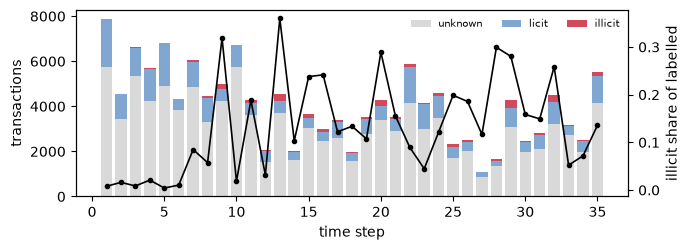

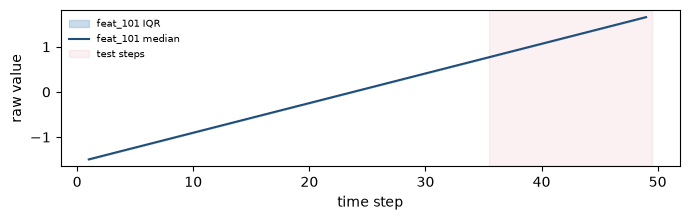

In [3]:
# Count labels per time step, measure drift in feat_101, compare the graph shape of illicit and licit
# transactions, and draw two plots.
labelled_rows = X_ALL[X_ALL.label.notna()]
labels_by_step = (X_ALL[X_ALL.split == "train"].groupby("time_step").label
            .agg(illicit=lambda s: (s == 1).sum(), licit=lambda s: (s == 0).sum(),
                 unknown=lambda s: s.isna().sum()))
labels_by_step["illicit_share"] = labels_by_step.illicit / (labels_by_step.illicit + labels_by_step.licit)

print(f"labelled: {len(labelled_rows):,} of {(X_ALL.split == 'train').sum():,} train rows "
      f"({len(labelled_rows) / (X_ALL.split == 'train').sum():.1%}); "
      f"illicit share among labelled: {labelled_rows.label.mean():.1%}")
print(f"illicit share per step: {labels_by_step.illicit_share.min():.1%} to {labels_by_step.illicit_share.max():.1%}")
print(f"missing feature values: {int(X_ALL[FEAT_COLS].isna().sum().sum())}")
print(f"corr(feat_101, time_step): {X_ALL.feat_101.corr(X_ALL.time_step):.3f}")
# check that every link joins two transactions in the same time step
e_ts = edges.txId1.map(dict(zip(tx_steps.txId, tx_steps.time_step)))
e_ts2 = edges.txId2.map(dict(zip(tx_steps.txId, tx_steps.time_step)))
both = e_ts.notna() & e_ts2.notna()
print(f"edges inside one time step (both ends known): {(e_ts[both] == e_ts2[both]).mean():.1%}")

# graph shape of illicit vs licit transactions
shape = pd.DataFrame({
    "one input": labelled_rows.graph_in_degree.eq(1),
    "one input, one output": labelled_rows.graph_in_degree.eq(1) & labelled_rows.graph_out_degree.eq(1),
    "no edges": labelled_rows.graph_degree.eq(0),
}).groupby(labelled_rows.label.map({0: "licit", 1: "illicit"}).values).mean()
display(shape.round(3))

# Figure 1: labels per step and illicit share
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(labels_by_step.index, labels_by_step.unknown, color="#d9d9d9", label="unknown")
ax.bar(labels_by_step.index, labels_by_step.licit, bottom=labels_by_step.unknown, color="#7fa7d1", label="licit")
ax.bar(labels_by_step.index, labels_by_step.illicit, bottom=labels_by_step.unknown + labels_by_step.licit,
       color="#d1495b", label="illicit")
ax.set_xlabel("time step")
ax.set_ylabel("transactions")
ax2 = ax.twinx()
ax2.plot(labels_by_step.index, labels_by_step.illicit_share, color="black", lw=1.2, marker=".",
         label="illicit share")
ax2.set_ylabel("illicit share of labelled")
ax.legend(loc="upper right", fontsize=7, ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_labels_per_step.png", dpi=200)
plt.show()

# Figure 2: feat_101 rises over time; test steps shaded
q = X_ALL.groupby("time_step").feat_101.quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots(figsize=(7, 2.3))
ax.fill_between(q.index, q[0.25], q[0.75], color="#7fa7d1", alpha=0.4, label="feat_101 IQR")
ax.plot(q.index, q[0.5], color="#1f4e79", label="feat_101 median")
ax.axvspan(35.5, 49.5, color="#d1495b", alpha=0.08, label="test steps")
ax.set_xlabel("time step")
ax.set_ylabel("raw value")
ax.legend(loc="upper left", fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_drift.png", dpi=200)
plt.show()

## 4. Neighbour links
Three sparse matrices link each transaction to the transactions it pays (out), the ones that pay it (in), and
both. `neighbour_scores(s)` takes one predicted risk score per transaction and returns the average and maximum
score of its neighbours in each direction. These 6 columns are the neighbour information used in stacking
(section 6).

58,437 links end at a transaction with no features, all of them in the test steps. These ends all point to one
shared row (row 0), so the links still count towards a transaction's neighbours.

In [4]:
# Link each transaction to the ones it pays and the ones that pay it, so a model can use its
# neighbours' predicted risk scores.
row_of = {t: i for i, t in enumerate(X_ALL.txId.values)}
# edge ends with no feature row all point to one shared row, so these links still count
MISSING_ROW = 0
src = edges.txId1.map(row_of).fillna(MISSING_ROW).astype(int).values
dst = edges.txId2.map(row_of).fillna(MISSING_ROW).astype(int).values
ADJ_OUT = sp.csr_matrix((np.ones(len(src)), (src, dst)), shape=(N_TX, N_TX))  # row i -> who i pays
ADJ_IN = ADJ_OUT.T.tocsr()                                                     # row i -> who pays i
ADJ_BOTH = ((ADJ_OUT + ADJ_IN) > 0).astype(float).tocsr()                      # row i -> all its neighbours
# average and highest neighbour score, for in, out and both directions (6 columns)
NEIGHBOUR_COLS = [f"nb_{k}_{a}" for k in ("in", "out", "u") for a in ("mean", "max")]
print(f"edges with a featureless endpoint: {int((edges.txId1.map(row_of).isna() | edges.txId2.map(row_of).isna()).sum()):,}")


def neighbour_scores(s):
    """Average and highest predicted risk of each transaction's in-, out- and all neighbours (6 columns)."""
    feats = {}
    for name, M in (("in", ADJ_IN), ("out", ADJ_OUT), ("u", ADJ_BOTH)):
        degree = np.asarray(M.sum(1)).ravel()                  # number of neighbours
        feats[f"nb_{name}_mean"] = (M @ s) / np.maximum(degree, 1)  # average neighbour score
        top = np.zeros(N_TX)
        Mc = M.tocoo()
        np.maximum.at(top, Mc.row, s[Mc.col])                  # highest neighbour score
        feats[f"nb_{name}_max"] = top
    return feats

edges with a featureless endpoint: 58,437


## 5. Feature selection
Each feature gets two scores, both from LightGBM:
1. How much it changed over time. A classifier learns to tell earlier transactions from later ones using features
   only (3-fold, no labels). The features it relies on most are the ones that drift.
2. How useful it is for predicting illicit activity: how often a classifier trained on the labelled earlier
   transactions uses it.

Each feature is then kept, converted to a rank, or dropped:

| change over time (rank) | usefulness (rank) | decision |
|---|---|---|
| top 30 | top 60 | convert to its percentile rank (`REPLACE_WITH_RANK`) |
| top 30 | below 60 | drop (`DROP`) |
| below 30 | any | keep as it is (`KEEP_RAW`) |

Finally the kept features are sorted by importance and the top K are used.

The selection runs twice: steps 1–21 against 22–35 for the time-based validation, and steps 1–35 against the test
set for the submission. The validation therefore never uses a feature list chosen with its own labels.

The 44 features used for the submission are saved in the code as `TOP44`, so a library update cannot change them.
The cell below rebuilds the list from the data and prints whether it matches.

In [5]:
# Score each feature on how much it changed over time and how useful it is, then keep it, convert it
# to a rank, or drop it.
SELECTION_PARAMS = dict(learning_rate=0.03, max_depth=4, num_leaves=31, min_child_samples=20,
                        reg_alpha=0.1, reg_lambda=5.0, subsample=1.0, colsample_bytree=0.9)


def selection_rule(drift_rank, label_rank):
    """Keep a feature, convert it to a rank, or drop it, based on its two ranks."""
    if drift_rank <= 30:  # one of the 30 features that changed most over time
        return "REPLACE_WITH_RANK" if label_rank <= 60 else "DROP"  # keep as a rank only if useful
    return "KEEP_RAW"


def score_features(early, late, labelled):
    """Score every base feature on how much it changed over time and how useful it is."""
    # change over time: train a model to tell earlier from later transactions (no labels used)
    X_adv = pd.concat([early[BASE_COLS], late[BASE_COLS]], ignore_index=True)
    y_adv = np.r_[np.zeros(len(early)), np.ones(len(late))]
    drift = np.zeros(len(BASE_COLS))
    for fit_idx, _ in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_adv, y_adv):
        m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=SEED,
                               n_jobs=N_JOBS, verbosity=-1)
        drift += m.fit(X_adv.iloc[fit_idx], y_adv[fit_idx]).feature_importances_ / 3
    # usefulness: train a model to tell illicit from licit transactions
    y = labelled.label.astype(int)
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=SEED,
                           n_jobs=N_JOBS, verbosity=-1, scale_pos_weight=(y == 0).sum() / (y == 1).sum())
    d = pd.DataFrame({"feature": BASE_COLS, "drift_score": drift,
                      "label_score": m.fit(labelled[BASE_COLS], y).feature_importances_})
    d["drift_rank"] = d.drift_score.rank(ascending=False)
    d["label_rank"] = d.label_score.rank(ascending=False)
    d["decision"] = [selection_rule(a, b) for a, b in zip(d.drift_rank, d.label_rank)]
    return d


def rank_kept(decisions, labelled):
    """Sort the features that pass the rule by importance, most used first."""
    cols = (decisions.loc[decisions.decision == "KEEP_RAW", "feature"].tolist()
            + rank_names(decisions.loc[decisions.decision == "REPLACE_WITH_RANK", "feature"]))
    y = labelled.label.astype(int)
    m = lgb.LGBMClassifier(n_estimators=500, random_state=SEED, n_jobs=N_JOBS, verbosity=-1,
                           scale_pos_weight=0.5 * (y == 0).sum() / (y == 1).sum(), **SELECTION_PARAMS)
    return pd.Series(m.fit(labelled[cols], y).feature_importances_, index=cols).sort_values(ascending=False)


def select_features(last_train_step, late_mask):
    """Run the selection using labels from steps 1 to last_train_step only."""
    early = X_ALL[(X_ALL.split == "train") & (X_ALL.time_step <= last_train_step)]
    labelled = early[early.label.notna()]
    decisions = score_features(early, X_ALL[late_mask], labelled)
    return decisions, rank_kept(decisions, labelled)


# rows to score: the test set, or the validation steps 22-35
TEST_MASK = (X_ALL.split == "test").to_numpy()
CHECK_MASK = ((X_ALL.split == "train") & X_ALL.time_step.between(22, 35)).to_numpy()

# The 44 columns this selection gives for steps 1-35 vs test (stable across reruns).
# The submission uses the saved list, so a library update that reorders near-tied columns cannot change it.
TOP44 = ["feat_53", "feat_2_rank", "feat_132", "feat_59", "feat_23", "feat_3", "feat_125", "feat_5_rank",
         "feat_64", "feat_46", "feat_138", "feat_52", "feat_90", "feat_142", "feat_8_rank", "feat_131",
         "feat_139", "feat_161", "feat_40_rank", "feat_127", "feat_47", "feat_89_rank", "feat_107",
         "feat_55", "feat_17", "feat_100_rank", "feat_61", "feat_154_rank", "feat_109", "feat_137",
         "feat_136_rank", "feat_80", "feat_77", "feat_102_rank", "feat_88", "feat_73", "feat_41",
         "feat_143", "feat_65", "feat_130", "feat_18_rank", "feat_76_rank", "feat_91", "feat_58_rank"]

decisions_final, ranked_final = select_features(35, TEST_MASK)
print("steps 1-35 vs test:", decisions_final.decision.value_counts().to_dict(),
      f"-> {len(ranked_final)} candidate columns")
display(decisions_final.sort_values("drift_rank").head(12).set_index("feature")
        [["drift_rank", "label_rank", "decision"]].astype({"drift_rank": int, "label_rank": int}).T)
print("selected top 44:", list(ranked_final.index[:44]))
print("matches the saved TOP44:", list(ranked_final.index[:44]) == TOP44)

if RUN_TIME_CHECK:
    _, ranked_check = select_features(21, CHECK_MASK)  # feature list for the time-based validation

steps 1-35 vs test: {'KEEP_RAW': 142, 'REPLACE_WITH_RANK': 19, 'DROP': 11} -> 161 candidate columns


feature,feat_1,feat_136,graph_component_size,feat_154,feat_100,feat_101,feat_2,feat_103,graph_in_degree,graph_pagerank,feat_157,feat_18
drift_rank,1,2,3,4,5,6,7,8,9,10,11,12
label_rank,75,45,37,47,23,38,1,73,119,26,38,35
decision,DROP,REPLACE_WITH_RANK,REPLACE_WITH_RANK,REPLACE_WITH_RANK,REPLACE_WITH_RANK,REPLACE_WITH_RANK,REPLACE_WITH_RANK,DROP,DROP,REPLACE_WITH_RANK,REPLACE_WITH_RANK,REPLACE_WITH_RANK


selected top 44: ['feat_53', 'feat_2_rank', 'feat_132', 'feat_59', 'feat_23', 'feat_3', 'feat_125', 'feat_5_rank', 'feat_64', 'feat_46', 'feat_138', 'feat_52', 'feat_90', 'feat_142', 'feat_8_rank', 'feat_131', 'feat_139', 'feat_161', 'feat_40_rank', 'feat_127', 'feat_47', 'feat_89_rank', 'feat_107', 'feat_55', 'feat_17', 'feat_100_rank', 'feat_61', 'feat_154_rank', 'feat_109', 'feat_137', 'feat_136_rank', 'feat_80', 'feat_77', 'feat_102_rank', 'feat_88', 'feat_73', 'feat_41', 'feat_143', 'feat_65', 'feat_130', 'feat_18_rank', 'feat_76_rank', 'feat_91', 'feat_58_rank']
matches the saved TOP44: True


## 6. Models and neighbour-score stacking
**Feature views.** Each model in the ensemble sees one set of features:

| view | features |
|---|---|
| `top_k` | the K selected features |
| `top_k_ranks` | `top_k` plus the percentile rank of all 172 base features |
| `local_ranks` | ranks of `feat_1`–`feat_94` (the transaction's own features) |
| `aggregate` | raw `feat_95`–`feat_165` (features that summarise its neighbourhood) |

**Models.** LightGBM and XGBoost use 800 trees, a learning rate of 0.02, depth 6 and 60% of the features per tree.
ExtraTrees and Random Forest use 400 trees each. XGBoost is only used in the comparison in section 7.

**Class imbalance.** Illicit transactions get a higher training weight, set by the ratio of licit to illicit
transactions (`scale_pos_weight` for boosting, `balanced_subsample` for the forests). Unlabelled transactions can
also be added as weak examples of legitimate activity with a small weight (0.05 or 0.15), because some of them
could be illicit. Labelled transactions have weight 1.

**Neighbour-score stacking** (`stacked_scores`) runs in stages:
1. Initial prediction: predict each transaction's risk from its own features.
2. Neighbour information: add the average and maximum predicted risk of its neighbours as 6 new features.
3. Refined prediction: predict again, and repeat with the updated neighbour scores.

The risk scores for training transactions are out-of-fold. The training steps are split into 5 blocks of
consecutive steps, and each block is scored by a model that did not train on it (500 trees). This keeps a
transaction's own label out of its neighbour features. The transactions being evaluated or submitted are scored
by a model trained on all training steps (800 trees).

`set_split` chooses the steps to train on and hides every label outside them before any model is fitted.

In [6]:
# Define the feature views, the models and the neighbour-score stacking.
def set_views(top_k):
    """Set the four feature views a model can be trained on."""
    global VIEWS
    VIEWS = {
        "top_k": top_k,                                                # the K selected features
        "top_k_ranks": list(dict.fromkeys(top_k + rank_names(BASE_COLS))),  # plus every feature's rank
        "local_ranks": rank_names([f"feat_{i}" for i in range(1, 95)]),     # the transaction's own features
        "aggregate": [f"feat_{i}" for i in range(95, 166)],                 # its neighbourhood summary
    }


LGB_PARAMS = dict(learning_rate=0.02, max_depth=6, num_leaves=63, min_child_weight=5, reg_alpha=0.0,
                  reg_lambda=0.5, subsample=1.0, colsample_bytree=0.6)
XGB_PARAMS = dict(learning_rate=0.02, max_depth=6, min_child_weight=5, reg_alpha=0.0,
                  reg_lambda=0.5, subsample=1.0, colsample_bytree=0.6)


def make_model(kind, seed, spw, n_estimators):
    """Create one untrained model: 'lgb', 'xgb', 'et' (ExtraTrees) or 'rf' (Random Forest)."""
    if kind == "lgb":
        return lgb.LGBMClassifier(n_estimators=n_estimators, scale_pos_weight=spw, random_state=seed,
                                  n_jobs=N_JOBS, verbose=-1, **LGB_PARAMS)
    if kind == "xgb":
        return xgb.XGBClassifier(n_estimators=n_estimators, scale_pos_weight=spw, random_state=seed,
                                 n_jobs=N_JOBS, verbosity=0, tree_method="hist", **XGB_PARAMS)
    if kind == "et":
        return ExtraTreesClassifier(n_estimators=400, min_samples_leaf=3, max_features=0.3,
                                    class_weight="balanced_subsample", random_state=seed, n_jobs=N_JOBS)
    return RandomForestClassifier(n_estimators=400, min_samples_leaf=2, max_features=0.3,
                                  class_weight="balanced_subsample", random_state=seed, n_jobs=N_JOBS)


def fit_and_score(X_fit, y_fit, w_fit, X_pred, kind, n_estimators, seeds):
    """Train one model per seed and return their average predicted risk for X_pred."""
    # illicit weight = licit rows / illicit rows (unlabelled rows count as licit here)
    spw = (y_fit == 0).sum() / max((y_fit == 1).sum(), 1)
    preds = []
    for seed in seeds:
        m = make_model(kind, seed, spw, n_estimators)
        m.fit(X_fit, y_fit, sample_weight=w_fit)
        preds.append(m.predict_proba(X_pred)[:, 1])
    return np.mean(preds, axis=0)


def set_split(last_train_step, score_mask):
    """Choose the steps to train on and the rows to score, and hide every label outside the training steps."""
    global IN_TRAIN, SCORE_ROWS, TRAIN_LABELS, OOF_BLOCKS
    IN_TRAIN = ((X_ALL.split == "train") & (X_ALL.time_step <= last_train_step)).to_numpy()
    score_mask = np.asarray(score_mask, dtype=bool)
    assert not np.any(IN_TRAIN & score_mask)
    SCORE_ROWS = np.flatnonzero(score_mask)
    TRAIN_LABELS = np.where(IN_TRAIN, X_ALL.label.to_numpy(), np.nan)
    OOF_BLOCKS = np.array_split(np.arange(1, last_train_step + 1), 5)  # 5 blocks for out-of-fold scores
    assert np.isnan(TRAIN_LABELS[SCORE_ROWS]).all()  # no label of a scored row can be used


def fit_rows(X, feats, exclude_steps, unknown_weight):
    """Build the training data; unlabelled transactions become weak legitimate examples if unknown_weight > 0."""
    keep = IN_TRAIN & ~X.time_step.isin(exclude_steps).values
    lab = keep & ~np.isnan(TRAIN_LABELS)
    unl = keep & np.isnan(TRAIN_LABELS)
    if unknown_weight <= 0:
        return X.iloc[np.where(lab)[0]][feats].values, TRAIN_LABELS[lab].astype(int), None
    rows = np.r_[np.where(lab)[0], np.where(unl)[0]]
    y = np.r_[TRAIN_LABELS[lab].astype(int), np.zeros(unl.sum(), int)]
    w = np.r_[np.ones(lab.sum()), np.full(unl.sum(), unknown_weight)]
    return X.iloc[rows][feats].values, y, w


def stacked_scores(stage_views, kind="lgb", unknown_weight=0.05, seeds=(SEED,), oof_final=False):
    """Neighbour-score stacking: every stage after the first also sees its neighbours' predicted risk."""
    extra = {}
    for stage, view in enumerate(stage_views):
        X = X_ALL.assign(**extra) if extra else X_ALL
        feats = VIEWS[view] + (NEIGHBOUR_COLS if stage > 0 else [])  # stage 1: own features only
        last = stage == len(stage_views) - 1
        s = np.zeros(N_TX)
        if not last or oof_final:
            # out-of-fold scores for training rows: each block is scored by a model (500 trees) not trained on it
            for block in OOF_BLOCKS:
                Xf, yf, wf = fit_rows(X, feats, block, unknown_weight)
                rows = np.where(IN_TRAIN & X.time_step.isin(block).values)[0]
                s[rows] = fit_and_score(Xf, yf, wf, X.iloc[rows][feats].values, kind, 500, (SEED,))
        # rows being evaluated or submitted: a model (800 trees) trained on all training steps
        Xf, yf, wf = fit_rows(X, feats, [], unknown_weight)
        s[SCORE_ROWS] = fit_and_score(Xf, yf, wf, X.iloc[SCORE_ROWS][feats].values, kind, 800, seeds)
        if not last:
            extra = neighbour_scores(s)  # neighbour information for the next stage
    return s[SCORE_ROWS]


to_rank = lambda x: rankdata(x) / len(x)  # scores -> ranks in (0, 1]

## 7. Time-based validation: number of features and boosting model
The test set covers the 14 time steps after training, so the validation does the same: train on steps 1–21 and
evaluate on steps 22–35 (11,705 labelled transactions, 1,773 illicit). Shorter validation periods of 1–6 steps
gave ROC-AUC above 0.99 for almost every model, which was too optimistic to tell models apart.

I test 30, 44 and 60 features with LightGBM and XGBoost, using the main model of the ensemble (three stacking
stages on the `top_k` view, unlabelled weight 0.05, 3 seeds). K = 44 is the default. Another K replaces it only if
it scores at least 0.005 higher for both algorithms, which is about the difference between random seeds.

In [7]:
# Time-based validation: compare 30, 44 and 60 features with LightGBM and XGBoost.
K = 44
if RUN_TIME_CHECK:
    set_split(21, CHECK_MASK)  # train on steps 1-21, evaluate on 22-35
    y_check = X_ALL.label.to_numpy()[SCORE_ROWS]
    labelled = ~np.isnan(y_check)                     # unlabelled rows are left out of the metrics
    check_auc = lambda p: roc_auc_score(y_check[labelled], p[labelled])

    t0 = perf_counter()
    sweep = []
    for k in K_CANDIDATES:
        set_views(list(ranked_check.index[:k]))
        for kind in ("lgb", "xgb"):
            score = stacked_scores(("top_k",) * 3, kind, 0.05, SEEDS, oof_final=True)
            sweep.append({"K": k, "model": kind, "auc": check_auc(score)})
    sweep = pd.DataFrame(sweep).pivot(index="K", columns="model", values="auc")
    print(f"comparison fitted in {(perf_counter() - t0) / 60:.1f} min")
    display(sweep.round(4))

    # change K from 44 only if another K is clearly better for both models
    winners = [k for k in sweep.index if k != 44 and (sweep.loc[k] - sweep.loc[44] >= 0.005).all()]
    K = max(winners, key=lambda k: sweep.loc[k].mean()) if winners else 44
print(f"K = {K}")

comparison fitted in 5.5 min


model,lgb,xgb
K,,
30,0.8631,0.8516
44,0.8629,0.8858
60,0.8690,0.8728


K = 44


XGBoost scored highest with 44 features (0.886 against 0.863 for LightGBM), but its score changed more across
feature counts (0.852–0.886) than LightGBM's (0.863–0.869). So the ensemble uses LightGBM, and K stays at 44.
With LightGBM, the full ensemble scores 0.848 on the validation steps and 0.96974 on the public leaderboard.

## 8. Final ensemble
The ensemble combines 11 models with a weighted average of their prediction rankings. Each model's scores are
turned into ranks between 0 and 1 before averaging. ROC-AUC only depends on the order of the scores, and ranks put
models with different score scales on the same footing.

Three models are first averaged into a core, each over 3 seeds:
- three stacking stages on `top_k` (weight 3);
- `top_k`, then `top_k_ranks` (weight 1);
- one stage on `local_ranks` (weight 1).

The core is then combined with 8 other models that vary the feature view, the algorithm (LightGBM, ExtraTrees,
Random Forest) and the weight given to unlabelled transactions. The core and the other models built on the top 44
features hold 7 of the 12 weight units. The rest get weight 1 and add information from other feature sets.

I set the weights by hand rather than tuning them. The validation split has only about 11,700 labelled
transactions, so weights tuned on it would mostly fit its noise.

The ensemble is first evaluated on the validation steps, then retrained for the submission in section 9.

In [8]:
# Combine 11 models into one score with a weighted average of their prediction rankings.
BOOST = "lgb"


def run_ensemble():
    """Build the 11 models and average their prediction rankings with fixed weights."""
    three_topk = ("top_k",) * 3
    core_parts = [  # the core: 3 models, each averaged over 3 seeds
        (stacked_scores(three_topk, BOOST, 0.05, SEEDS, oof_final=True), 3),
        (stacked_scores(("top_k", "top_k_ranks"), BOOST, 0.05, SEEDS, oof_final=True), 1),
        (stacked_scores(("local_ranks",), BOOST, 0.0, SEEDS), 1),
    ]
    core = to_rank(sum(to_rank(p) * w for p, w in core_parts) / sum(w for _, w in core_parts))
    members = [  # (scores, weight); stacked_scores(view per stage, algorithm, unlabelled weight)
        (core, 1),  # the core above
        (stacked_scores(("top_k_ranks",) * 3, BOOST, 0.15), 1),  # top 44 plus all ranks
        (stacked_scores(three_topk, BOOST, 0.15), 3),  # top 44, LightGBM
        (stacked_scores(three_topk, "et", 0.05), 2),  # top 44, ExtraTrees
        (stacked_scores(("aggregate",) * 3, BOOST, 0.05), 1),  # neighbourhood features
        (stacked_scores(three_topk, "rf", 0.0), 1),  # top 44, Random Forest
        (stacked_scores(("aggregate",) * 3, BOOST, 0.15), 1),  # neighbourhood features
        (stacked_scores(("local_ranks",) * 3, BOOST, 0.15), 1),  # own-feature ranks
        (stacked_scores(("aggregate",) * 3, BOOST, 0.0), 1),  # neighbourhood features, no unlabelled rows
    ]
    return sum(to_rank(p) * w for p, w in members) / sum(w for _, w in members)


# evaluate the ensemble on the validation steps 22-35
if RUN_TIME_CHECK:
    t0 = perf_counter()
    set_views(list(ranked_check.index[:K]))
    check_score = run_ensemble()
    print(f"ensemble fitted in {(perf_counter() - t0) / 60:.1f} min")
    print(f"time-based check ROC-AUC (steps 22-35): {check_auc(check_score):.4f}")

    # ROC-AUC for each validation step
    per_step = pd.DataFrame({"ts": X_ALL.time_step.values[SCORE_ROWS], "y": y_check,
                             "score": check_score})[labelled]
    by_step = per_step.groupby("ts").apply(lambda g: pd.Series({"illicit": int(g.y.sum()),
                                                                "roc_auc": roc_auc_score(g.y, g.score)}))
    display(by_step.round(3).T)

ensemble fitted in 9.8 min
time-based check ROC-AUC (steps 22-35): 0.8483


ts,22,23,24,25,26,27,28,29,30,31,32,33,34,35
illicit,158.000,53.000,137.00,118.0,96.000,24.000,85.0,329.000,83.000,106.000,342.000,23.000,37.000,182.000
roc_auc,0.999,0.932,0.62,1.0,0.901,0.999,1.0,0.631,0.995,0.718,0.754,0.999,0.997,0.996


ROC-AUC is above 0.99 in most validation steps but falls to about 0.62–0.75 in steps 24, 29, 31 and 32. In those
steps the illicit transactions look different from earlier ones, so a model trained on earlier steps ranks them
lower (Figure 3).

**Precision, recall and F1.** ROC-AUC needs no cut-off: it is the chance that a random illicit transaction scores
above a random licit one. Precision, recall and F1 need a yes or no answer, so I flag the top-scored transactions
as illicit. In training steps 1–21, 9.6% of labelled transactions are illicit, so the main cut-off flags the top
9.6%. It is fixed before the validation steps are scored, so it uses none of their labels. The other rows show how
precision and recall change when more or fewer transactions are flagged.

ROC-AUC (no cut-off needed): 0.8483
illicit share of labelled training rows (steps 1-21): 9.6% -> main cut-off


,n flagged,illicit among flagged,precision,recall,F1
flagged,,,,,
top 9.6% (main),1122,1112,0.9911,0.6272,0.7682
top 5.0%,586,586,1.0000,0.3305,0.4968
top 10.0%,1171,1153,0.9846,0.6503,0.7833
top 15.0%,1756,1314,0.7483,0.7411,0.7447


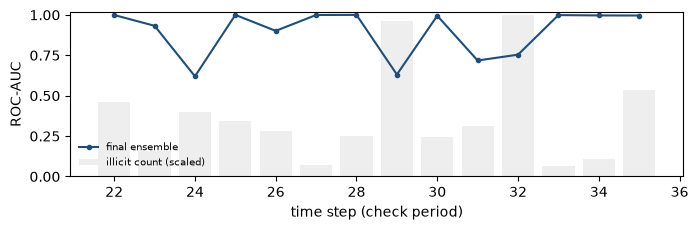

In [9]:
# ROC-AUC, then precision, recall and F1 when the top-scored transactions are flagged as illicit.
if RUN_TIME_CHECK:
    y_lab, s_lab = y_check[labelled].astype(int), check_score[labelled]
    # main cut-off fixed before scoring: the illicit share of the labelled training rows (steps 1-21)
    train_share = np.nanmean(TRAIN_LABELS[IN_TRAIN])
    print(f"ROC-AUC (no cut-off needed): {roc_auc_score(y_lab, s_lab):.4f}")
    print(f"illicit share of labelled training rows (steps 1-21): {train_share:.1%} -> main cut-off")
    rows = []
    for share in (train_share, 0.05, 0.10, 0.15):
        flag = s_lab >= np.quantile(s_lab, 1 - share)  # flag the top `share` of transactions as illicit
        rows.append({"flagged": f"top {share:.1%}" + (" (main)" if share == train_share else ""),
                     "n flagged": int(flag.sum()), "illicit among flagged": int((flag & (y_lab == 1)).sum()),
                     "precision": precision_score(y_lab, flag), "recall": recall_score(y_lab, flag),
                     "F1": f1_score(y_lab, flag)})
    display(pd.DataFrame(rows).set_index("flagged").round(4))

    # Figure 3: ROC-AUC per validation step
    fig, ax = plt.subplots(figsize=(7, 2.4))
    ax.bar(by_step.index, by_step.illicit / by_step.illicit.max(), color="#eeeeee", label="illicit count (scaled)")
    ax.plot(by_step.index, by_step.roc_auc, color="#1f4e79", marker="o", ms=3, label="final ensemble")
    ax.set_xlabel("time step (check period)")
    ax.set_ylabel("ROC-AUC")
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower left", fontsize=7, frameon=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig3_auc_by_step.png", dpi=200)
    plt.show()

## 9. Retrain on steps 1–35 and write the submission
The same ensemble, now trained on all 35 training steps with the saved 44 features, scores the test transactions.

In [10]:
# Retrain the ensemble on steps 1-35 with the saved 44 features, score the test transactions and
# write the submission file.
t0 = perf_counter()
set_split(35, TEST_MASK)
set_views(TOP44 if K == 44 else list(ranked_final.index[:K]))
final_score = run_ensemble()
print(f"ensemble fitted in {(perf_counter() - t0) / 60:.1f} min")

# the file must match the sample submission row for row
assert np.array_equal(X_ALL.txId.values[SCORE_ROWS], test.txId.values)
submission = pd.DataFrame({"index": test["index"].values, "target": final_score})
assert len(submission) == len(sample) == 15329
assert list(submission.columns) == ["index", "target"]
assert submission["index"].equals(sample["index"])
assert np.isfinite(submission.target).all() and submission.target.between(0, 1).all()

out_path = OUT_DIR / "e1122390.csv"
submission.to_csv(out_path, index=False)
print(f"wrote {out_path.relative_to(ROOT)} ({len(submission):,} rows)")
print(f"total runtime {(perf_counter() - START) / 60:.1f} min")

ensemble fitted in 16.5 min
wrote Submission/e1122390.csv (15,329 rows)
total runtime 32.1 min
